# Question 9: Image Segmentation Using Clustering

This notebook performs **image segmentation** using K-Means and Gaussian Mixture Model (GMM) clustering on color images. Each pixel is represented by a 5-dimensional feature vector:
1. Normalized vertical position (row)
2. Normalized horizontal position (column)
3. Red channel (normalized)
4. Green channel (normalized)
5. Blue channel (normalized)

Normalization ensures that all features are in the unit hypercube [0,1]^5, preventing scale bias in clustering.

In [9]:
# Import required libraries
import numpy as np
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from skimage import io, color, img_as_float
import matplotlib.pyplot as plt

## Function: Segment Image

This function builds the 5D feature vector for each pixel, normalizes the spatial coordinates, and applies K-Means or GMM clustering.

In [10]:
def segment_image(image_path, K, algorithm="kmeans"):
    img = io.imread(image_path)
    img = img_as_float(img)  # Convert to float in [0,1]
    height, width, _ = img.shape

    # Build 5D feature vector: normalized row, col, R, G, B
    pixels = []
    for r in range(height):
        for c in range(width):
            x_norm = r / (height - 1)
            y_norm = c / (width - 1)
            r_norm, g_norm, b_norm = img[r, c]
            pixels.append([x_norm, y_norm, r_norm, g_norm, b_norm])
    pixels = np.array(pixels)

    # Perform clustering
    if algorithm.lower() == "kmeans":
        model = KMeans(n_clusters=K, random_state=0, n_init=10)
        labels = model.fit_predict(pixels)
    elif algorithm.lower() == "gmm":
        model = GaussianMixture(n_components=K, random_state=0)
        labels = model.fit_predict(pixels)
    else:
        raise ValueError("Algorithm must be 'kmeans' or 'gmm'")

    labels = labels.reshape(height, width)
    return labels

## Function: Visualize Segmentation

Each cluster label is mapped to a distinct color for better contrast using `label2rgb`.

In [11]:
def visualize_segmentation(labels, image_path, title=""):
    img = io.imread(image_path)
    segmented_img = color.label2rgb(labels, image=img, bg_label=-1, kind='avg')

    plt.figure(figsize=(8,6))
    plt.imshow(segmented_img)
    plt.title(title)
    plt.axis('off')
    plt.show()

## Apply Segmentation on Multiple Images

We segment `image1.jpg` and `image2.jpg` using K-Means and GMM for K = 2, 3, 4, 5.

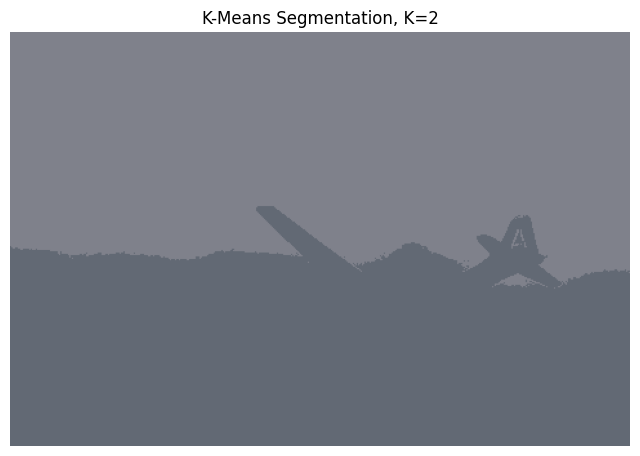

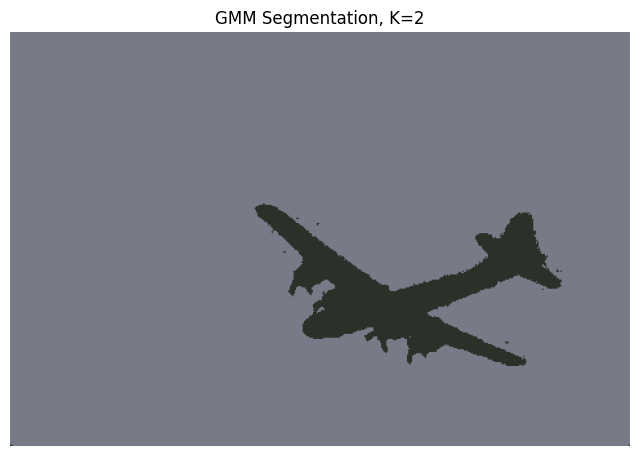

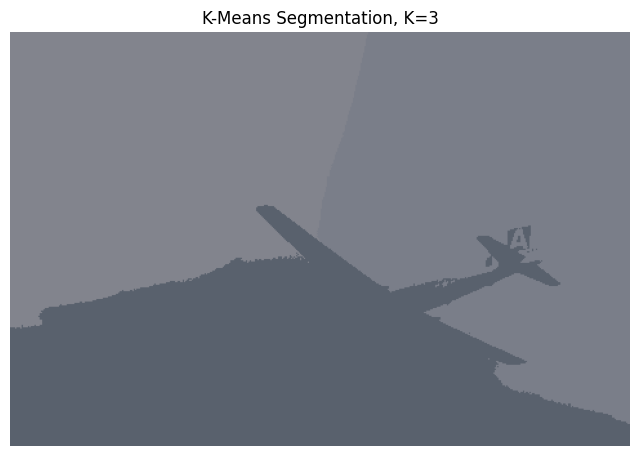

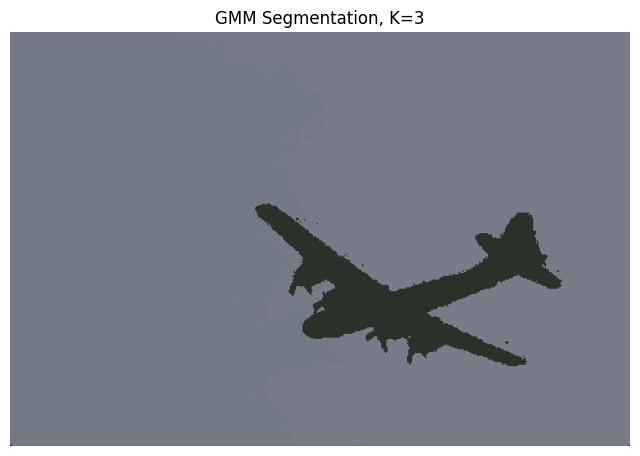

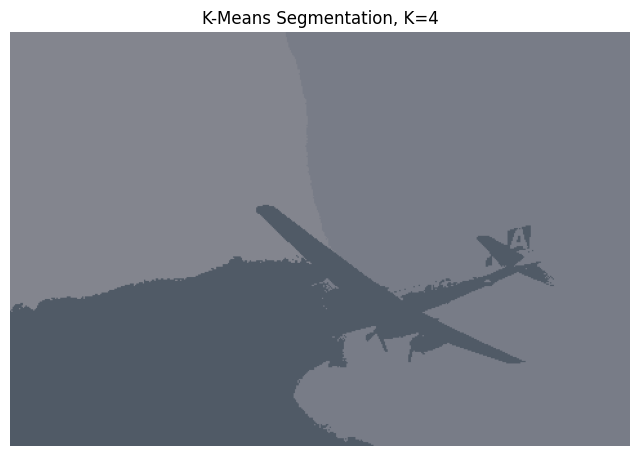

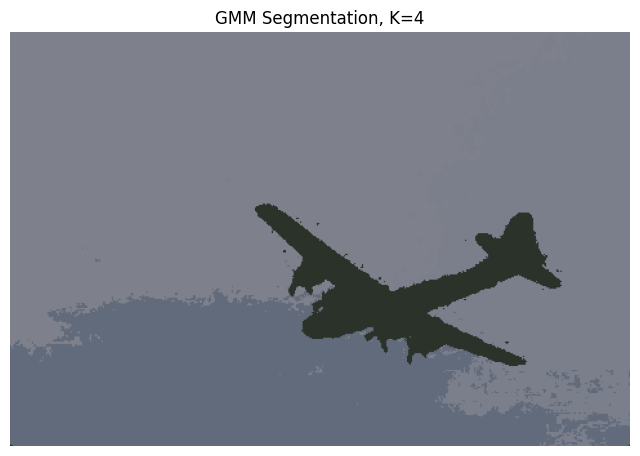

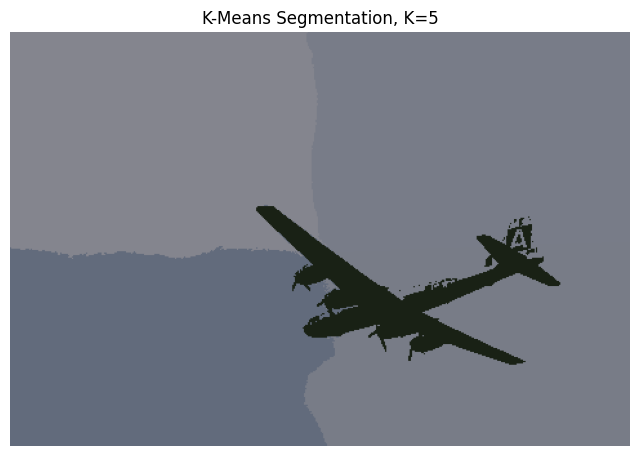

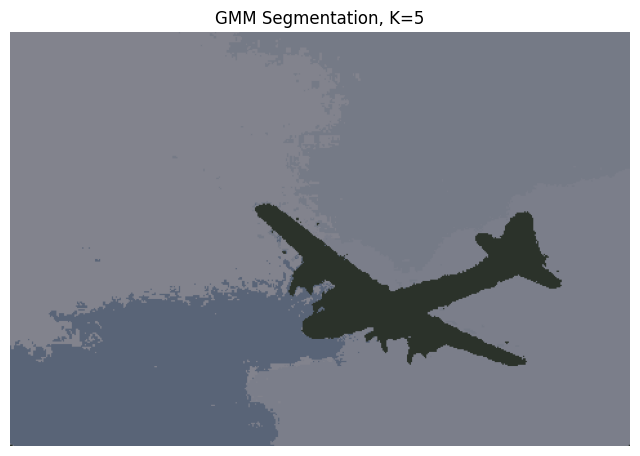

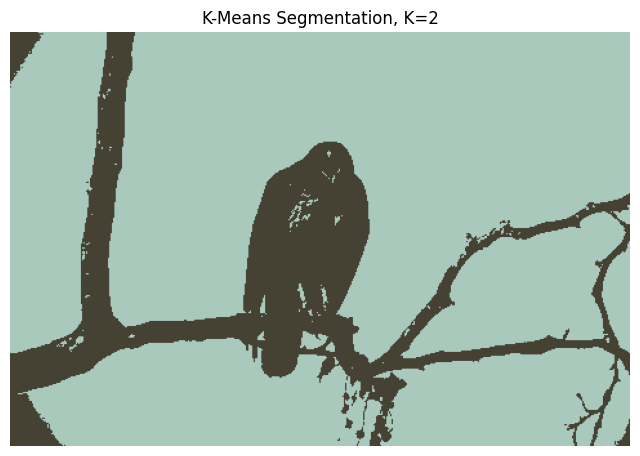

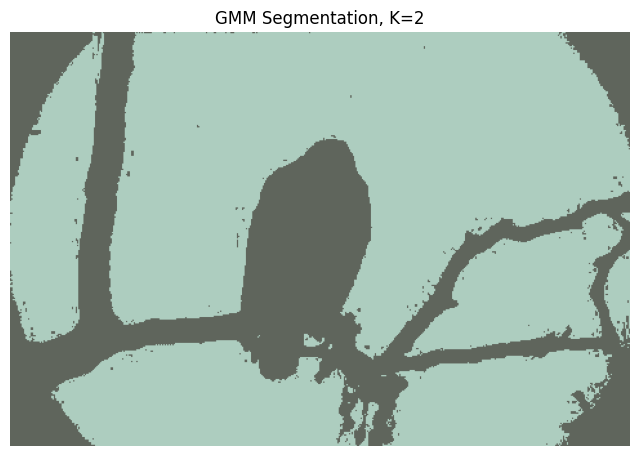

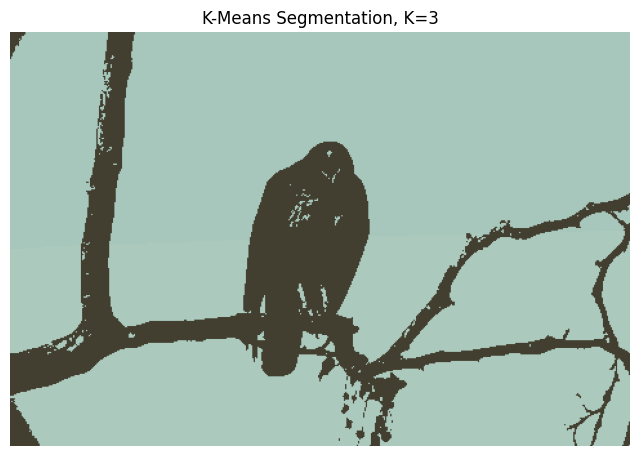

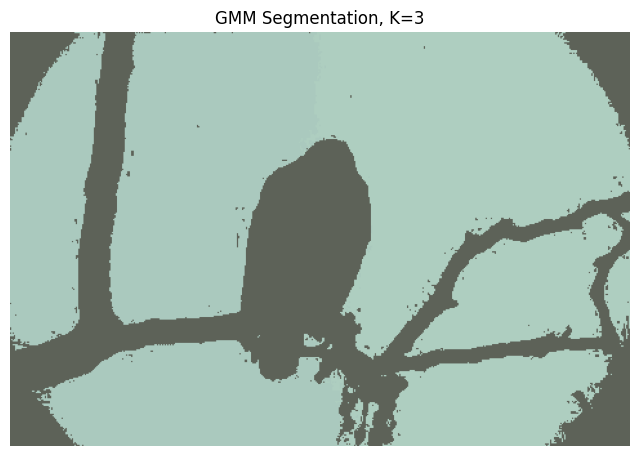

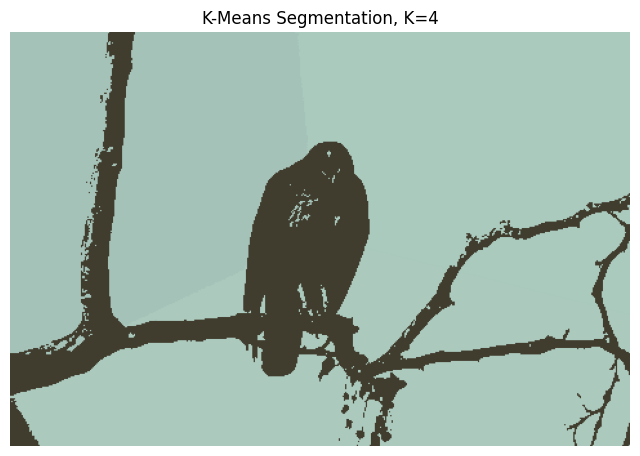

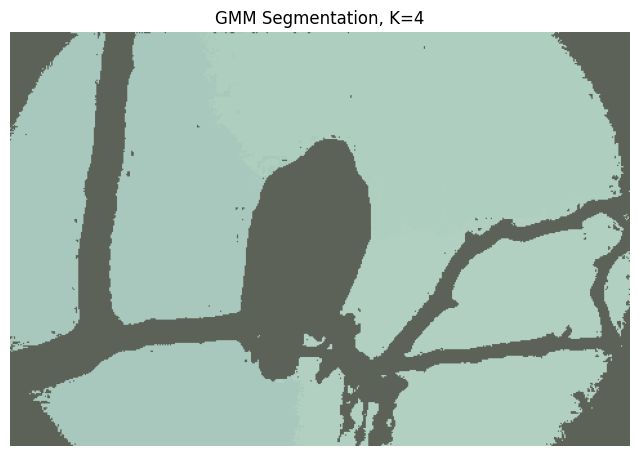

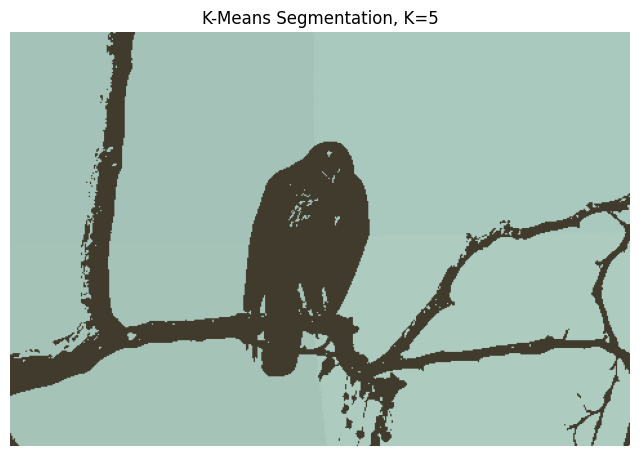

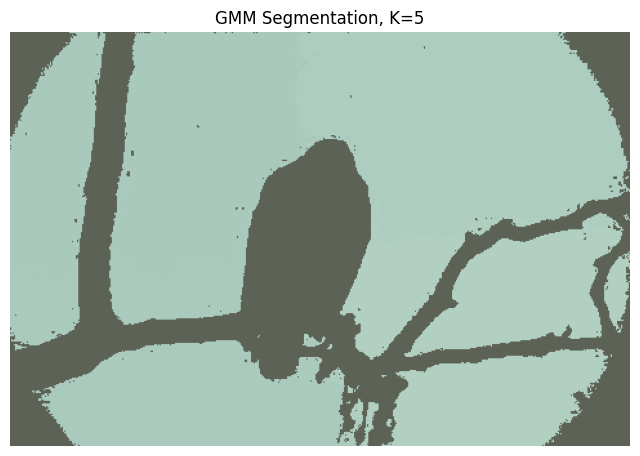

In [12]:
images = ["image1.jpg", "image2.jpg"]
cluster_counts = [2, 3, 4, 5]

for image_path in images:
    for K in cluster_counts:
        # K-Means
        labels_kmeans = segment_image(image_path, K, algorithm="kmeans")
        visualize_segmentation(labels_kmeans, image_path, title=f"K-Means Segmentation, K={K}")

        # GMM
        labels_gmm = segment_image(image_path, K, algorithm="gmm")
        visualize_segmentation(labels_gmm, image_path, title=f"GMM Segmentation, K={K}")

## Observations

- **K-Means:** Hard assignment, may produce blocky boundaries.
- **GMM:** Soft assignment, smoother boundaries.
- Including normalized pixel coordinates helps spatial coherence.
- Increasing K gives more detailed segments but can over-segment.
- Normalization ensures that RGB values do not dominate spatial features.